<a href="https://colab.research.google.com/github/hsb-ctrl-zy/multi-team1-project/blob/main/%EC%BD%94%EB%9E%A9/%ED%94%84%EB%A1%AC%ED%94%84%ED%8A%B8_AB_%ED%85%8C%EC%8A%A4%ED%8A%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 필요 라이브러리 설치 및 로드

In [ ]:
!pip install pymysql

In [ ]:
import pymysql

### SQL 연결

In [ ]:
#데이터베이스 연결
conn=pymysql.connect(
    host=host_name,
    user=user_name,
    password=password_val,
    database=db_name,
    port=port_num,
    charset='utf8'
)

### MySQL 연결 상태 확인

In [ ]:
if conn:
    try:
        # 커서를 생성하여 쿼리 실행 준비
        with conn.cursor() as cursor:
            # 간단한 쿼리로 현재 연결된 데이터베이스 이름을 확인
            cursor.execute("SELECT DATABASE();")
            result = cursor.fetchone()
            if result and result[0]:
                print(f"데이터베이스 연결이 성공적으로 확인되었습니다. 현재 데이터베이스: {result[0]}")
            else:
                print("데이터베이스에 연결되었지만, 현재 데이터베이스 이름을 가져올 수 없습니다.")
    except pymysql.Error as e:
        print(f"데이터베이스 연결 확인 중 오류 발생: {e}")
        print("연결에 문제가 있을 수 있습니다.")
else:
    print("데이터베이스 연결 객체(conn)가 생성되지 않았습니다. 연결이 실패했을 수 있습니다.")

데이터베이스 연결이 성공적으로 확인되었습니다. 현재 데이터베이스: geo_db


### 데이터 추출, 3-Way Join 병합 및 JSON 전처리 함수 정의

연관 컬럼
1. raw_data_table 의 page_id
2. eval_session_table의 query_id
3. eval_log_table의 page_id

In [ ]:
import pandas as pd
import json
import re

# 1. DB 데이터 추출 함수 정의
def fetch_data(query):
    with conn.cursor() as cursor:
        cursor.execute(query)
        columns = [desc[0] for desc in cursor.description]
        data = cursor.fetchall()
        return pd.DataFrame(data, columns=columns)

In [ ]:
# 2. 3-Way Join 쿼리로 데이터 병합
correct_merge_query = """
SELECT
    e.session_id,
    e.is_corrected,
    e.strictness_level,
    e.eval_sys_prompt_ver,
    l.page_id,
    r.json_ld_contents AS original_json_ld,
    g.json_ld_code AS corrected_json_ld,
    g.cor_sys_prompt_ver
FROM eval_session_table e
JOIN eval_log_table l ON e.session_id = l.session_id
LEFT JOIN raw_data_table r ON l.page_id = r.page_id
LEFT JOIN geo_correction_table g ON l.page_id = g.page_id;
"""

df_ab = fetch_data(correct_merge_query)

In [ ]:
# 3. 줄바꿈 및 특수문자 정제 후 JSON-LD 유효성 검증하는 전처리 함수
def clean_and_validate_json_ld(json_str):
    if pd.isna(json_str) or json_str is None:
        return False

    try:
        text = str(json_str).strip()
        # 마크다운 코드블록 태그 제거
        text = re.sub(r'^```(?:json)?\s*', '', text, flags=re.IGNORECASE)
        text = re.sub(r'\s*```$', '', text)

        # 줄바꿈(\n, \r) 및 제어문자를 공백으로 정제 (JSONParseError 방지)
        text = re.sub(r'[\r\n\t]+', ' ', text)

        # JSON 파싱
        data = json.loads(text)

        # 리스트 중첩 해제 ([[ ... ]] -> [ ... ])
        if isinstance(data, list) and len(data) == 1 and isinstance(data[0], list):
            data = data[0]

        if isinstance(data, list):
            if not data:
                return False
            for item in data:
                if not (isinstance(item, dict) and '@context' in item and '@type' in item):
                    return False
            return True
        elif isinstance(data, dict):
            return '@context' in data and '@type' in data
        else:
            return False

    except Exception:
        return False

print("데이터 통합 완료! 총 행 수:", len(df_ab))

데이터 통합 완료! 총 행 수: 328800


### 유효성 검증 및 A/B 테스트 결과 산출

In [ ]:
# 1. 원본 및 교정본 유효성 검증 적용
df_ab['is_valid_original'] = df_ab['original_json_ld'].apply(clean_and_validate_json_ld)
df_ab['is_valid_corrected'] = df_ab['corrected_json_ld'ㅋ].apply(clean_and_validate_json_ld)

In [ ]:
# 2. 대조군(is_corrected=0)과 실험군(is_corrected=1) 분리
control = df_ab[df_ab['is_corrected'] == 0]
treatment = df_ab[df_ab['is_corrected'] == 1]

In [ ]:
# 3. 최종 A/B 테스트 리포트 출력
control_rate = control['is_valid_original'].mean() * 100
treatment_orig_rate = treatment['is_valid_original'].mean() * 100
treatment_corr_rate = treatment['is_valid_corrected'].mean() * 100

print("="*45)
print("          A/B 테스트 최종 분석 리포트          ")
print("="*45)
print(f"1. 대조군 (is_corrected=0) [건수: {len(control):,}건]")
print(f"   - 원본 JSON-LD 유효율 : {control_rate:.2f}%\n")
print(f"2. 실험군 (is_corrected=1) [건수: {len(treatment):,}건]")
print(f"   - 교정 전 (원본) 유효율 : {treatment_orig_rate:.2f}%")
print(f"   - 교정 후 (프롬프트) 유효율 : {treatment_corr_rate:.2f}%")
print("-"*45)
print(f"★ 프롬프트 교정 효과 (유효율 변화) : {treatment_corr_rate - treatment_orig_rate:+.2f}%p")
print("="*45)

          A/B 테스트 최종 분석 리포트          
1. 대조군 (is_corrected=0) [건수: 164,400건]
   - 원본 JSON-LD 유효율 : 85.69%

2. 실험군 (is_corrected=1) [건수: 164,400건]
   - 교정 전 (원본) 유효율 : 85.69%
   - 교정 후 (프롬프트) 유효율 : 0.22%
---------------------------------------------
★ 프롬프트 교정 효과 (유효율 변화) : -85.47%p


In [ ]:
# 교정본 실패 원인 분석
error_list = []

for text in df_ab[df_ab['is_corrected'] == 1]['corrected_json_ld']:
    if pd.isna(text) or text is None:
        error_list.append("NULL / Empty")
        continue

    # 정제 시도
    cleaned = re.sub(r'^```(?:json)?\s*', '', str(text).strip(), flags=re.IGNORECASE)
    cleaned = re.sub(r'\s*```$', '', cleaned)
    cleaned = re.sub(r'[\r\n\t]+', ' ', cleaned)

    try:
        data = json.loads(cleaned)
        if isinstance(data, list) and len(data) == 1:
            data = data[0]

        if isinstance(data, dict):
            if '@context' not in data:
                error_list.append("Schema Error: @context 없음")
            elif '@type' not in data:
                error_list.append("Schema Error: @type 없음")
            else:
                error_list.append("정상 (Valid)")
        else:
            error_list.append("Type Error: Dict 형태 아님")
    except json.JSONDecodeError as e:
        error_list.append(f"JSON 문법 오류 ({e.msg})")
    except Exception as e:
        error_list.append(f"기타 오류: {type(e).__name__}")

print("=== 교정본(corrected_json_ld) 파싱 실패 원인 Top 5 ===")
print(pd.Series(error_list).value_counts().head(5))

=== 교정본(corrected_json_ld) 파싱 실패 원인 Top 5 ===
NULL / Empty                            147960
Schema Error: @type 없음                   12540
JSON 문법 오류 (Expecting ',' delimiter)      3540
정상 (Valid)                                 360
Name: count, dtype: int64


↑ <데이터 정제 및 파싱 실패 원인 규명>

결측치 발생: Join 특성상 교정이 수행되지 않은 페이지 데이터까지 포섭되어 전체(318460행) 중 138,114건의 NULL 데이터 발생.


In [ ]:
import pandas as pd
import json
import re

# 1. 교정 데이터(corrected_json_ld)가 실제로 존재하는 행만 필터링
df_valid_geo = df_ab[df_ab['corrected_json_ld'].notna() & (df_ab['corrected_json_ld'] != '')].copy()

# 2. JSON 파싱 가능 여부 및 스키마 유효성 검증 함수
def validate_json_only(json_str):
    try:
        text = str(json_str).strip()
        text = re.sub(r'^```(?:json)?\s*', '', text, flags=re.IGNORECASE)
        text = re.sub(r'\s*```$', '', text)
        text = re.sub(r'[\r\n\t]+', ' ', text)

        data = json.loads(text)
        if isinstance(data, list) and len(data) == 1:
            data = data[0]

        # JSON 문법적으로 파싱만 되면 성공 처리 (필요시 @context 조건만 확인)
        return isinstance(data, (dict, list))
    except Exception:
        return False

# 3. 유효성 재계산
df_valid_geo['is_valid_orig'] = df_valid_geo['original_json_ld'].apply(validate_json_only)
df_valid_geo['is_valid_corr'] = df_valid_geo['corrected_json_ld'].apply(validate_json_only)

print("=== 실제 교정 실행 데이터(NULL 제외) 대상 최종 리포트 ===")
print(f"- 분석 대상 건수: {len(df_valid_geo):,}건")
print(f"- 원본(교정 전) JSON 파싱 성공률: {df_valid_geo['is_valid_orig'].mean()*100:.2f}%")
print(f"- 교정본(교정 후) JSON 파싱 성공률: {df_valid_geo['is_valid_corr'].mean()*100:.2f}%")

=== 실제 교정 실행 데이터(NULL 제외) 대상 최종 리포트 ===
- 분석 대상 건수: 32,880건
- 원본(교정 전) JSON 파싱 성공률: 100.00%
- 교정본(교정 후) JSON 파싱 성공률: 78.47%


↑

분석 대상: corrected_json_ld가 존재하는 유효 교정 데이터 31,846건

교정 전 (원본) 파싱 성공률: 100.00%

교정 후 (LLM 프롬프트) 파싱 성공률: 78.92%


### 프롬프트 교정 전/후 JSON-LD 규격 이행률 분석

[1단계] JSON-LD 필수 규격 이행률 측정 (문법 & 스키마)

- ① 문법 정상 파싱, ② @context 존재, ③ @type 존재 3가지 조건 비교

In [ ]:
import pandas as pd
import json
import re

# 1. 교정 데이터가 존재하는 31,846건 대상
df_analysis = df_valid_geo.copy()

In [ ]:
# 2. 세부 규격 검증 함수 정의
def check_json_ld_compliance(json_str):
    res = {
        'syntax_ok': False,      # 문법 파싱 성공 여부
        'has_context': False,    # @context 포함 여부
        'has_type': False,       # @type 포함 여부
        'full_compliance': False # 3가지 조건 모두 만족 여부
    }

    if pd.isna(json_str) or json_str is None:
        return res

    try:
        text = str(json_str).strip()
        text = re.sub(r'^```(?:json)?\s*', '', text, flags=re.IGNORECASE)
        text = re.sub(r'\s*```$', '', text)
        text = re.sub(r'[\r\n\t]+', ' ', text)

        data = json.loads(text)
        res['syntax_ok'] = True

        if isinstance(data, list) and len(data) > 0:
            data = data[0]

        if isinstance(data, dict):
            res['has_context'] = '@context' in data
            res['has_type'] = '@type' in data

        res['full_compliance'] = res['syntax_ok'] and res['has_context'] and res['has_type']
    except Exception:
        pass

    return res

In [ ]:
# 3. 교정 전(원본) vs 교정 후 적용
orig_results = pd.DataFrame(df_analysis['original_json_ld'].apply(check_json_ld_compliance).tolist())
corr_results = pd.DataFrame(df_analysis['corrected_json_ld'].apply(check_json_ld_compliance).tolist())

In [ ]:
# 4. 규격 이행률 비교 리포트 출력
print("="*60)
print("     [1단계] 프롬프트 교정 전/후 JSON-LD 규격 이행률 세부 비교     ")
print("="*60)
print(f"분석 대상 건수: {len(df_analysis):,}건\n")

metrics = [
    ('1. JSON 문법 통과율 (Syntax Check)', 'syntax_ok'),
    ('2. @context 필드 존재율', 'has_context'),
    ('3. @type 필드 존재율', 'has_type'),
    ('★ 최종 완전 규격 이행률 (Full Compliance)', 'full_compliance')
]

for label, col in metrics:
    orig_rate = orig_results[col].mean() * 100
    corr_rate = corr_results[col].mean() * 100
    diff = corr_rate - orig_rate
    print(f"📌 {label}")
    print(f"   - 교정 전 (원본) : {orig_rate:.2f}%")
    print(f"   - 교정 후 (프롬프트): {corr_rate:.2f}%")
    print(f"   - 이행률 변화량  : {diff:+.2f}%p\n")

     [1단계] 프롬프트 교정 전/후 JSON-LD 규격 이행률 세부 비교     
분석 대상 건수: 32,880건

📌 1. JSON 문법 통과율 (Syntax Check)
   - 교정 전 (원본) : 100.00%
   - 교정 후 (프롬프트): 78.47%
   - 이행률 변화량  : -21.53%p

📌 2. @context 필드 존재율
   - 교정 전 (원본) : 100.00%
   - 교정 후 (프롬프트): 78.47%
   - 이행률 변화량  : -21.53%p

📌 3. @type 필드 존재율
   - 교정 전 (원본) : 100.00%
   - 교정 후 (프롬프트): 2.19%
   - 이행률 변화량  : -97.81%p

📌 ★ 최종 완전 규격 이행률 (Full Compliance)
   - 교정 전 (원본) : 100.00%
   - 교정 후 (프롬프트): 2.19%
   - 이행률 변화량  : -97.81%p



↑
@type 필드 존재율이 2.26%로 급락하는 현상이 최종 규격 이행률(-97.74%p)을 떨어뜨린 핵심 원인

[2단계] @type 누락 패턴 및 JSON 변환 형태 정밀 진단

- LLM이 교정본을 출력 시 @type 키를 누락시킨 이유 진단

  - 후보1. 키 이름 변형: @type 대신 type, @Type, type_name 등으로 잘못 생성

  - 후보2. 구조 변형 : 데이터를 객체( { } )가 아닌 문자열이나 단순 배열로 변환

  - 후보3. 완전 누락: 키 자체를 지워버리고 생략함

In [ ]:
# LLM의 @type 누락 및 키 변형 패턴 분석
type_patterns = []

for item in df_analysis['corrected_json_ld']:
    if pd.isna(item) or item is None:
        continue

    try:
        text = str(item).strip()
        text = re.sub(r'^```(?:json)?\s*', '', text, flags=re.IGNORECASE)
        text = re.sub(r'\s*```$', '', text)
        text = re.sub(r'[\r\n\t]+', ' ', text)

        data = json.loads(text)
        if isinstance(data, list) and len(data) > 0:
            data = data[0]

        if isinstance(data, dict):
            # 키 파악 (대소문자 및 유사 키 탐색)
            keys = [str(k).lower() for k in data.keys()]
            if '@type' in data:
                type_patterns.append("정상 (@type 존재)")
            elif 'type' in keys:
                type_patterns.append("키 변형: 'type' (골뱅이 누락)")
            elif '@type' in [k.lower() for k in data.keys()]:
                type_patterns.append("키 변형: 대소문자 혼동 (예: @Type)")
            else:
                type_patterns.append("완전 누락 (@type 관련 키 전혀 없음)")
        else:
            type_patterns.append("구조 오류 (Dict 형태 아님)")

    except Exception:
        type_patterns.append("JSON 문법 파싱 실패 건")

In [ ]:
print("="*60)
print("     [2단계] 교정본의 @type 누락 및 변형 패턴 세부 분석     ")
print("="*60)
pattern_series = pd.Series(type_patterns)
for pattern, count in pattern_series.value_counts().items():
    ratio = (count / len(type_patterns)) * 100
    print(f"• {pattern:<35}: {count:,}건 ({ratio:.2f}%)")

     [2단계] 교정본의 @type 누락 및 변형 패턴 세부 분석     
• 완전 누락 (@type 관련 키 전혀 없음)           : 25,080건 (76.28%)
• JSON 문법 파싱 실패 건                    : 7,080건 (21.53%)
• 정상 (@type 존재)                      : 720건 (2.19%)


↑

키 이름 변형(type, @Type 등)이 발생한 것이 아니라,

전체의 76.66%가 아예 @type 키 자체가 완전 누락됨

[3단계] @type 누락 데이터의 실제 키 구조 확인 & 결함 분류 요약

- LLM이 @type을 지우는 대신 어떤 필드들(예: name, address, description 등)만 출력했는지 패턴을 파악 및 최종 결함 유형 통계 산출


In [ ]:
# @type 완전 누락 건들의 최상위 Key 구조 분석
missing_type_keys = []

for item in df_analysis['corrected_json_ld']:
    if pd.isna(item) or item is None:
        continue
    try:
        text = str(item).strip()
        text = re.sub(r'^```(?:json)?\s*', '', text, flags=re.IGNORECASE)
        text = re.sub(r'\s*```$', '', text)
        text = re.sub(r'[\r\n\t]+', ' ', text)

        data = json.loads(text)
        if isinstance(data, list) and len(data) > 0:
            data = data[0]

        if isinstance(data, dict) and '@type' not in data:
            # 주요 존재하는 키들의 조합 추출
            k_tuple = tuple(sorted(list(data.keys())))
            missing_type_keys.append(k_tuple)
    except Exception:
        pass

In [ ]:
print("="*60)
print("   [3단계] @type 누락 데이터에 존재하는 주요 Key 조합 Top 5   ")
print("="*60)
key_series = pd.Series(missing_type_keys)
for keys, count in key_series.value_counts().head(5).items():
    ratio = (count / len(missing_type_keys)) * 100
    print(f"• 존재 Key: {list(keys)}")
    print(f"  └ 건수: {count:,}건 ({ratio:.2f}%)\n")

   [3단계] @type 누락 데이터에 존재하는 주요 Key 조합 Top 5   
• 존재 Key: ['@context', '@graph']
  └ 건수: 25,080건 (100.00%)



↑

LLM이 최상위 루트 객체에 @type을 넣는 대신, @graph 구조(배열 내부에 여러 노드를 넣는 포맷)로 변환하여 교정 결과를 출력

@graph 내부에 @type이 숨어있을 가능성 O

[4단계] @graph 내부의 @type 존재 여부 정밀 확인

- @graph 구조 내부 배열 항목에 @type이 정상적으로 들어있는지(구조 변환 문제), 아니면 누락되어 있는지(규격 위반)


In [ ]:
# @graph 내부 노드들의 @type 존재 여부 검증
graph_type_results = []

for item in df_analysis['corrected_json_ld']:
    if pd.isna(item) or item is None:
        continue
    try:
        text = str(item).strip()
        text = re.sub(r'^```(?:json)?\s*', '', text, flags=re.IGNORECASE)
        text = re.sub(r'\s*```$', '', text)
        text = re.sub(r'[\r\n\t]+', ' ', text)

        data = json.loads(text)
        if isinstance(data, list) and len(data) > 0:
            data = data[0]

        if isinstance(data, dict):
            # 1. 최상위에 @type이 있는 경우
            if '@type' in data:
                graph_type_results.append("최상위 @type 존재 (단일 객체)")
            # 2. @graph 구조인 경우 내부 노드 탐색
            elif '@graph' in data and isinstance(data['@graph'], list):
                has_inner_type = any(
                    isinstance(node, dict) and '@type' in node
                    for node in data['@graph']
                )
                if has_inner_type:
                    graph_type_results.append("@graph 내부 @type 존재 (그래프 구조)")
                else:
                    graph_type_results.append("@graph 내부에도 @type 없음")
            else:
                graph_type_results.append("완전 누락")
    except Exception:
        graph_type_results.append("JSON 문법 오류")

In [ ]:
print("="*60)
print("   [4단계] JSON-LD 구조 재해석 후 실제 @type 규격 이행률   ")
print("="*60)
res_series = pd.Series(graph_type_results)
for res_type, count in res_series.value_counts().items():
    ratio = (count / len(graph_type_results)) * 100
    print(f"• {res_type:<35}: {count:,}건 ({ratio:.2f}%)")

   [4단계] JSON-LD 구조 재해석 후 실제 @type 규격 이행률   
• @graph 내부 @type 존재 (그래프 구조)        : 25,080건 (76.28%)
• JSON 문법 오류                         : 7,080건 (21.53%)
• 최상위 @type 존재 (단일 객체)               : 720건 (2.19%)


↑

JSON-LD의 표기 구조를 최상위 단일 객체에서 @graph 그래프 구조로 재구성

∴실제 JSON-LD 규격 이행률은 78.92%(@graph 76.66% + 단일 2.26%)로, 데이터 손실이나 스키마 누락이 아님

### --- 추가 규격 이행률 분석 ---
1) Description 글자 수 분량
2) 의류 도메인 필수 속성(material, color, size, category) 이행률
3) 신뢰도(Confidence/Certainty)
4) 엔티티(Entity) 추출 상태

[1단계] 세부 검증 항목 진단 함수 정의

- JSON-LD 객체 내에 지정한 4가지 요소를 파싱하여 수치화하는 검증 함수를 생성

In [ ]:
import json
import re
import pandas as pd


def analyze_detail_compliance(json_str):
    # 세부 규격 평가 지표 초기화
    res = {
        "syntax_ok": False,
        "desc_length": 0,  # Description 글자 수
        "desc_valid": False,  # 1. Description 이행률 (최소 20자 이상)
        "has_brand": False,  # 2-1. 의류 필수 속성: 브랜드
        "has_color": False,  # 2-2. 의류 필수 속성: 색상
        "has_size": False,  # 2-3. 의류 필수 속성: 사이즈/Offer
        "has_material": False, # 2-4. 의류 필수 속성: 소재
        "has_category": False, # 2-5. 의류 필수 속성: 카테고리
        "apparel_full_compliance": False,  # 2. 의류 필수 속성 전수 이행률 (5가지 모두 보유)
        "has_confidence": False,  # 3. 신뢰도(Confidence) 필드 이행률
        "entity_count": 0,  # 4. 엔티티 개수 (추출 노드/키 수)
    }

    if pd.isna(json_str) or not str(json_str).strip():
        return res

    try:
        # Markdown 태그 및 제어문자 정제
        text = str(json_str).strip()
        text = re.sub(r"^```(?:json)?\s*", "", text, flags=re.IGNORECASE)
        text = re.sub(r"\s*```$", "", text)
        text = re.sub(r"[\r\n\t]+", " ", text)

        data = json.loads(text)
        res["syntax_ok"] = True

        # @graph 또는 단일 루트 노드 파싱
        target_dict = {}
        if isinstance(data, list) and len(data) > 0:
            target_dict = data[0] if isinstance(data[0], dict) else {}
        elif isinstance(data, dict):
            if "@graph" in data and isinstance(data["@graph"], list):
                # @graph 내부 노드 중 Product/Clothing 타입 탐색
                products = [
                    item
                    for item in data["@graph"]
                    if isinstance(item, dict)
                    and item.get("@type") in ["Product", "Clothing"]
                ]
                target_dict = (
                    products[0]
                    if products
                    else (
                        data["@graph"][0]
                        if isinstance(data["@graph"][0], dict)
                        else {}
                    )
                )
                res["entity_count"] = len(data["@graph"])
            else:
                target_dict = data
                res["entity_count"] = len(data.keys())

        if target_dict:
            # 1. Description 분량 진단 (20자 이상 시 규격 이행)
            desc = target_dict.get("description", "")
            if isinstance(desc, str):
                res["desc_length"] = len(desc)
                res["desc_valid"] = len(desc) >= 20

            # 2. 의류 도메인 필수 속성 진단
            res["has_brand"] = "brand" in target_dict
            res["has_color"] = "color" in target_dict
            res["has_size"] = any(
                k in target_dict for k in ["size", "offers", "hasVariant"]
            )
            res["has_material"] = "material" in target_dict
            res["has_category"] = "category" in target_dict

            res["apparel_full_compliance"] = (
                res["has_brand"] and res["has_color"] and res["has_size"] and res["has_material"] and res["has_category"]
            )

            # 3. 신뢰도(Confidence/Certainty) 필드 진단
            res["has_confidence"] = any(
                k in target_dict for k in ["confidence", "certainty"]
            )

    except Exception:
        pass

    return res

[2단계] 원본 vs 교정본 세부 비교 진단 실행

df_valid_geo 데이터프레임에 적용하여 교정 전/후 수치를 계산

In [ ]:
# 31,846건 유효 교정 데이터 대상 진단 수행
orig_detail = pd.DataFrame(
    df_valid_geo["original_json_ld"]
    .apply(analyze_detail_compliance)
    .tolist()
)
corr_detail = pd.DataFrame(
    df_valid_geo["corrected_json_ld"]
    .apply(analyze_detail_compliance)
    .tolist()
)

print("=" * 65)
print("  [세부 속성 기준] JSON-LD 규격 이행률 분석 리포트")
print("=" * 65)
print(f"분석 대상 건수: {len(df_valid_geo):,}건\n")

# 1. Description 이행률
print("📌 1. Description (설명 분량) 이행률")
print(
    f"   - 평균 글자 수       : {orig_detail['desc_length'].mean():.1f}자 ➔ {corr_detail['desc_length'].mean():.1f}자"
)
print(
    f"   - 규격 이행률(>=20자) : {orig_detail['desc_valid'].mean()*100:.2f}% ➔ {corr_detail['desc_valid'].mean()*100:.2f}%\n"
)

# 2. 의류 필수 속성 이행률
print("📌 2. 의류 도메인 필수 속성 이행률")
print(
    f"   - Brand 보유율      : {orig_detail['has_brand'].mean()*100:.2f}% ➔ {corr_detail['has_brand'].mean()*100:.2f}%"
)
print(
    f"   - Color 보유율      : {orig_detail['has_color'].mean()*100:.2f}% ➔ {corr_detail['has_color'].mean()*100:.2f}%"
)
print(
    f"   - Size/Offers 보유율 : {orig_detail['has_size'].mean()*100:.2f}% ➔ {corr_detail['has_size'].mean()*100:.2f}%"
)
print(
    f"   - Material 보유율    : {orig_detail['has_material'].mean()*100:.2f}% ➔ {corr_detail['has_material'].mean()*100:.2f}%"
)
print(
    f"   - Category 보유율    : {orig_detail['has_category'].mean()*100:.2f}% ➔ {corr_detail['has_category'].mean()*100:.2f}%"
)
print(
    f"   - [종합] 필수속성 완수율: {orig_detail['apparel_full_compliance'].mean()*100:.2f}% ➔ {corr_detail['apparel_full_compliance'].mean()*100:.2f}%\n"
)

# 3. 신뢰도 필드 이행률 및 엔티티 상태
print("📌 3. 신뢰도(Confidence) 및 엔티티(Entity) 추출 이행 상태")
print(
    f"   - 신뢰도 필드 존재율 : {orig_detail['has_confidence'].mean()*100:.2f}% ➔ {corr_detail['has_confidence'].mean()*100:.2f}%"
)
print(
    f"   - 평균 엔티티/속성 개수: {orig_detail['entity_count'].mean():.1f}개 ➔ {corr_detail['entity_count'].mean():.1f}개\n"
)

  [세부 속성 기준] JSON-LD 규격 이행률 분석 리포트
분석 대상 건수: 32,880건

📌 1. Description (설명 분량) 이행률
   - 평균 글자 수       : 60.3자 ➔ 69.1자
   - 규격 이행률(>=20자) : 25.91% ➔ 77.37%

📌 2. 의류 도메인 필수 속성 이행률
   - Brand 보유율      : 100.00% ➔ 77.37%
   - Color 보유율      : 0.00% ➔ 53.28%
   - Size/Offers 보유율 : 100.00% ➔ 77.37%
   - Material 보유율    : 0.00% ➔ 75.18%
   - Category 보유율    : 0.00% ➔ 75.18%
   - [종합] 필수속성 완수율: 0.00% ➔ 53.28%

📌 3. 신뢰도(Confidence) 및 엔티티(Entity) 추출 이행 상태
   - 신뢰도 필드 존재율 : 0.00% ➔ 0.00%
   - 평균 엔티티/속성 개수: 0.0개 ➔ 1.0개



In [ ]:
# 컬럼 존재 여부 확인 후 처리
if 'has_material' in corr_detail.columns:
    material_rate = corr_detail['has_material'].mean()
else:ㅋ
    print("Warning: 'has_material' 컬럼이 데이터프레임에 존재하지 않습니다.")

[3단계] 진단 결과 기반 문제점 감지 및 프롬프트 해결책 도출

1) Description 구간별 분포
2) 속성별 개별 누락 패턴
3) @graph 내 엔티티 타입별 분산

을 세분화하여 분석

In [ ]:
import json
import re
import pandas as pd


def analyze_detail_deep(json_str):
    res = {
        "syntax_ok": False,
        "desc_length": 0,
        "desc_category": "0) JSON 파싱 실패",  # 파싱 실패와 순수 누락 구분
        "has_brand": False,
        "has_color": False,
        "has_size": False,
        "has_material": False,
        "has_category": False,
        "missing_attrs": [],
        "has_confidence": False,
        "confidence_val": None,
        "is_graph": False,
        "graph_node_types": [],
        "root_keys_cnt": 0,
    }

    if pd.isna(json_str) or not str(json_str).strip():
        res["desc_category"] = "0) 데이터 없음 (NULL)"
        return res

    # 1. JSON 파싱 및 정제 시도
    try:
        text = str(json_str).strip()
        text = re.sub(r"^```(?:json)?\s*", "", text, flags=re.IGNORECASE)
        text = re.sub(r"\s*```$", "", text)
        text = re.sub(r"[\r\n\t]+", " ", text)

        data = json.loads(text)
        res["syntax_ok"] = True  # 파싱 성공 표기

    except Exception:
        # JSON 문법 오류 발생 시 바로 반환 (desc_category: "0) JSON 파싱 실패")
        return res

    # 2. 파싱 성공 객체 내에서 Target Dict 추출
    target = {}
    if isinstance(data, dict):
        if "@graph" in data and isinstance(data["@graph"], list):
            res["is_graph"] = True
            res["graph_node_types"] = [
                x.get("@type", "Unknown")
                for x in data["@graph"]
                if isinstance(x, dict)
            ]
            prods = [
                x
                for x in data["@graph"]
                if isinstance(x, dict)
                and x.get("@type") in ["Product", "Clothing"]
            ]
            target = (
                prods[0]
                if prods
                else (
                    data["@graph"][0]
                    if isinstance(data["@graph"][0], dict)
                    else {}
                )
            )
        else:
            target = data
            res["root_keys_cnt"] = len(data.keys())
    elif isinstance(data, list) and len(data) > 0:
        target = data[0] if isinstance(data[0], dict) else {}

    # 3. 파싱 성공 객체 대상 Description 및 속성 분석
    if target:
        desc = target.get("description", "")
        desc_str = str(desc).strip() if desc is not None else ""
        d_len = len(desc_str)
        res["desc_length"] = d_len

        # Description 구간별 분류 (파싱 성공 건에 대해서만 측정)
        if d_len == 0:
            res["desc_category"] = "1) 0자 (순수 누락)"
        elif d_len < 20:
            res["desc_category"] = "2) 1~19자 (단순 요약)"
        elif d_len < 50:
            res["desc_category"] = "3) 20~49자 (보통)"
        else:
            res["desc_category"] = "4) 50자 이상 (충실)"

        # 필수 속성 및 신뢰도 검증
        res["has_brand"] = "brand" in target
        res["has_color"] = "color" in target
        res["has_size"] = any(
            k in target for k in ["size", "offers", "hasVariant"]
        )
        res["has_material"] = "material" in target
        res["has_category"] = "category" in target

        missing = []
        if not res["has_brand"]:
            missing.append("brand")
        if not res["has_color"]:
            missing.append("color")
        if not res["has_size"]:
            missing.append("size/offers")
        if not res["has_material"]:
            missing.append("material")
        if not res["has_category"]:
            missing.append("category")
        res["missing_attrs"] = (
            " + ".join(missing) if missing else "없음 (전수 충족)"
        )

        if "confidence" in target:
            res["has_confidence"] = True
            res["confidence_val"] = target["confidence"]

    return res

In [ ]:
orig_deep = pd.DataFrame(
    df_valid_geo["original_json_ld"].apply(analyze_detail_deep).tolist()
)
corr_deep = pd.DataFrame(
    df_valid_geo["corrected_json_ld"].apply(analyze_detail_deep).tolist()
)

print("=" * 70)
print("             [디테일 심화 분석] JSON 규격 및 세부 속성 정밀 진단            ")
print("=" * 70)

# 1. Description 분포 세분화 (JSON 파싱 실패 vs 순수 누락 구분)
print("📌 1. Description 글자 수 구간별 비중 변화")
orig_desc_dist = orig_deep["desc_category"].value_counts(normalize=True) * 100
corr_desc_dist = corr_deep["desc_category"].value_counts(normalize=True) * 100

desc_df = pd.DataFrame(
    {"교정 전(%)": orig_desc_dist, "교정 후(%)": corr_desc_dist}
).fillna(0)
print(desc_df.sort_index().to_string())

# 2. 의류 속성 누락 조합 분석 (파싱 성공건 기준)
print("\n📌 2. 의류 필수 속성 결함 패턴 조합 Top 3 (교정 후)")
valid_corr = corr_deep[corr_deep["syntax_ok"]]
print(valid_corr["missing_attrs"].value_counts().head(3).to_string())

# 3. 신뢰도 및 엔티티 파편화 세부 진단
print("\n📌 3. 신뢰도 필드 및 엔티티 파편화 정밀 상태 (교정 후)")
print(
    f"  - 신뢰도(confidence) 필드 포함률 : {corr_deep['has_confidence'].mean()*100:.2f}%"
)
print(
    f"  - `@graph` 구조 변환 비율       : {corr_deep['is_graph'].mean()*100:.2f}%"
)

# Graph 노드 분포 세분화
all_nodes = [
    node for sublist in corr_deep["graph_node_types"] for node in sublist
]
if all_nodes:
    print("  - `@graph` 내부 추출 엔티티 타입 Top 3:")
    print(pd.Series(all_nodes).value_counts().head(3).to_string())

             [디테일 심화 분석] JSON 규격 및 세부 속성 정밀 진단            
📌 1. Description 글자 수 구간별 비중 변화
                    교정 전(%)    교정 후(%)
desc_category                         
0) JSON 파싱 실패      0.000000  21.532847
1) 0자 (순수 누락)     72.627737   1.094891
2) 1~19자 (단순 요약)   1.459854   0.000000
3) 20~49자 (보통)    16.788321   0.000000
4) 50자 이상 (충실)     9.124088  77.372263

📌 2. 의류 필수 속성 결함 패턴 조합 Top 3 (교정 후)
missing_attrs
없음 (전수 충족)                     17520
color                           7200
color + material + category      720

📌 3. 신뢰도 필드 및 엔티티 파편화 정밀 상태 (교정 후)
  - 신뢰도(confidence) 필드 포함률 : 0.00%
  - `@graph` 구조 변환 비율       : 76.28%
  - `@graph` 내부 추출 엔티티 타입 Top 3:
Product         25080
Organization     6240


In [ ]:
from google.colab import files
files.upload()

In [ ]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

ㅋ
plt.rcParams['axes.unicode_minus'] = False

# --- 사용자 제공 폰트 설정 ---
font_path = '/content/Pretendard－M.ttf'

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
    print(f"'{font_name}' 폰트 설정 완료.")
else:
    print(f"경로에 '{font_path}' 폰트 파일을 찾을 수 없습니다. 기본 폰트(나눔고딕 또는 대체 폰트)를 사용합니다.")
    try:
        fm.findfont('NanumGothic', rebuild_if_missing=True)
        plt.rc('font', family='NanumGothic')
        print("NanumGothic 폰트가 설치되어 있어 이를 사용합니다.")
    except Exception:
        plt.rc('font', family='DejaVu Sans')
        print("기본 폰트를 찾을 수 없어 'DejaVu Sans'를 사용합니다.")


# 모든 텍스트 및 축 요소 색상을 흰색으로 설정
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white' # 축 레이블 색상
plt.rcParams['xtick.color'] = 'white' # x축 틱 색상
plt.rcParams['ytick.color'] = 'white' # y축 틱 색상
plt.rcParams['axes.edgecolor'] = 'white' # 축 테두리 색상
plt.rcParams['figure.facecolor'] = 'none' # 그림 배경 투명화
plt.rcParams['savefig.facecolor'] = 'none' # 저장 시 배경 투명화
plt.rcParams['axes.facecolor'] = 'none' # 그래프 영역 배경 투명화

print("Matplotlib 한글 폰트 및 디자인 설정 완료 (Pretendard 폰트 파일을 업로드해야 제대로 적용됩니다).")

'Pretendard' 폰트 설정 완료.
Matplotlib 한글 폰트 및 디자인 설정 완료 (Pretendard 폰트 파일을 업로드해야 제대로 적용됩니다).


### 시각화

1.@type 존재

2.Description

3.의류 도메인 필수 속성

4.신뢰도

5.엔티티

In [ ]:
# 1. 안전한 컬럼 데이터 추출 함수 정의 (NameError 방지)
def get_field_rate(df, candidates):
    """후보 컬럼명 중 존재하는 컬럼의 평균 존재율(%)을 구하는 함수"""
    for col in candidates:
        if col in df.columns:
            return df[col].mean() * 100
    return 0.0

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import re

# 1. JSON-LD 상세 속성 파싱 함수 (의류 속성 & 신뢰도 포함)
def analyze_detail_properties(json_str):
    res = {
        'entity_count': 0,
        'attribute_count': 0,
        'has_brand': False,
        'has_material': False,
        'has_color': False,
        'has_size': False,
        'has_category': False,
        'apparel_full_compliance': False,
        'has_confidence': False,
        'desc_length': 0,
        'desc_valid': False
    }
    if pd.isna(json_str) or json_str is None:
        return res

    try:
        text = str(json_str).strip()
        text = re.sub(r'^```(?:json)?\s*', '', text, flags=re.IGNORECASE)
        text = re.sub(r'\s*```$', '', text)
        text = re.sub(r'[\r\n\t]+', ' ', text)
        data = json.loads(text)

        # Determine target_dict for properties, and count entities/attributes
        target_dict = {}
        processed_entities = []

        if isinstance(data, list):
            # If root is a list, process each item
            for item in data:
                if isinstance(item, dict):
                    processed_entities.append(item)
                elif isinstance(item, list) and len(item) == 1 and isinstance(item[0], dict):
                    processed_entities.append(item[0]) # Handle [[{...}]] case
            # If the list contains a single graph, extract its nodes
            if len(processed_entities) == 1 and '@graph' in processed_entities[0] and isinstance(processed_entities[0]['@graph'], list):
                processed_entities = [node for node in processed_entities[0]['@graph'] if isinstance(node, dict)]
            else:
                processed_entities = [item for item in data if isinstance(item, dict)] # Fallback for root-level list of dicts

        elif isinstance(data, dict):
            if "@graph" in data and isinstance(data["@graph"], list):
                processed_entities = [item for item in data['@graph'] if isinstance(item, dict)]
            else:
                processed_entities = [data] # Single root dictionary

        res['entity_count'] = len(processed_entities)
        res['attribute_count'] = sum(len(entity.keys()) for entity in processed_entities)

        # Select a target_dict for property extraction (e.g., first Product/Clothing, or first entity)
        products = [item for item in processed_entities if item.get("@type") in ["Product", "Clothing"]]
        target_dict = products[0] if products else (processed_entities[0] if processed_entities else {})


        if target_dict:
            # Description processing
            desc = target_dict.get("description", "")
            if isinstance(desc, str):
                res['desc_length'] = len(desc)
                res['desc_valid'] = len(desc) >= 20 # New: check for desc_valid

            # Attributes based on target_dict keys
            res['has_brand'] = 'brand' in target_dict
            res['has_material'] = 'material' in target_dict
            res['has_color'] = 'color' in target_dict
            res['has_size'] = any(k in target_dict for k in ['size', 'offers', 'hasVariant'])
            res['has_category'] = 'category' in target_dict

            # apparel_full_compliance calculation
            res['apparel_full_compliance'] = (
                res['has_brand'] and res['has_color'] and res['has_size'] and res['has_material'] and res['has_category']
            )

            # Confidence
            res['has_confidence'] = any(k in target_dict for k in ['confidence', 'conf_score', 'confidence_score', 'certainty'])

    except Exception:
        pass
    return res

In [ ]:
# 2. 데이터프레임 생성
orig_detail = pd.DataFrame(df_valid_geo['original_json_ld'].apply(analyze_detail_properties).tolist())
corr_detail = pd.DataFrame(df_valid_geo['corrected_json_ld'].apply(analyze_detail_properties).tolist())

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 시각화 데이터 준비 (기존 변수값 할당)
labels = ['교정 전', '교정 후']
colors = ['#71FFE7', '#FF7171']

# ① @type 존재율 (%)
def check_type_detail(json_str):
    res = {'root_type': False, 'graph_type': False, 'any_type': False}
    if pd.isna(json_str) or not json_str:
        return res
    try:
        text = str(json_str).strip()
        text = re.sub(r'^```(?:json)?\s*|\s*```$', '', text, flags=re.IGNORECASE)
        text = re.sub(r'[\r\n\t]+', ' ', text)
        data = json.loads(text)

        nodes = data if isinstance(data, list) else [data]
        for n in nodes:
            if not isinstance(n, dict):
                continue
            if '@type' in n:
                res['root_type'] = True
            if '@graph' in n and isinstance(n['@graph'], list):
                for g in n['@graph']:
                    if isinstance(g, dict) and '@type' in g:
                        res['graph_type'] = True
                        break
        res['any_type'] = res['root_type'] or res['graph_type']
    except Exception:
        pass
    return res

# 데이터프레임 실시간 적용 및 집계
orig_type_detail = pd.DataFrame(df_analysis['original_json_ld'].apply(check_type_detail).tolist())
corr_type_detail = pd.DataFrame(df_analysis['corrected_json_ld'].apply(check_type_detail).tolist())

# 교정 전/후 리스트 생성 (루트, @graph 내, 통합 순)
type_rate_orig = [
    orig_type_detail['root_type'].mean() * 100,
    orig_type_detail['graph_type'].mean() * 100,
    orig_type_detail['any_type'].mean() * 100
]

type_rate_corr = [
    corr_type_detail['root_type'].mean() * 100,
    corr_type_detail['graph_type'].mean() * 100,
    corr_type_detail['any_type'].mean() * 100
]

# ② Description 이행률 (분량 및 50자 이상 여부)
def check_description_detail(json_str):
    res = {'desc_len': 0, 'desc_over_50': False}
    if pd.isna(json_str) or not json_str:
        return res
    try:
        text = str(json_str).strip()
        text = re.sub(r'^```(?:json)?\s*|\s*```$', '', text, flags=re.IGNORECASE)
        text = re.sub(r'[\r\n\t]+', ' ', text)
        data = json.loads(text)

        nodes = data if isinstance(data, list) else [data]
        all_nodes = []
        for n in nodes:
            if isinstance(n, dict):
                all_nodes.append(n)
                if '@graph' in n and isinstance(n['@graph'], list):
                    all_nodes.extend([g for g in n['@graph'] if isinstance(g, dict)])

        # description 글자 수 및 50자 이상 여부 검증
        for n in all_nodes:
            desc = n.get('description', '')
            if isinstance(desc, str) and desc:
                length = len(desc)
                if length > res['desc_len']:
                    res['desc_len'] = length
                if length >= 50:
                    res['desc_over_50'] = True
    except Exception:
        pass
    return res

# 데이터프레임 적용 및 지표 산출
orig_desc_df = pd.DataFrame(df_analysis['original_json_ld'].apply(check_description_detail).tolist())
corr_desc_df = pd.DataFrame(df_analysis['corrected_json_ld'].apply(check_description_detail).tolist())

# [선택 1] 50자 이상 작성된 description 비율 (%)
desc_rate_over50 = [
    orig_desc_df['desc_over_50'].mean() * 100,
    corr_desc_df['desc_over_50'].mean() * 100
]

# [선택 2] 교정 전후 평균 description 분량 (글자 수)
desc_avg_len = [
    orig_desc_df['desc_len'].mean(),
    corr_desc_df['desc_len'].mean()
]

In [ ]:
# ③ 의류 도메인 필수 속성 이행률 (%)
apparel_attrs = ['Material', 'Color', 'Size', 'Category']
apparel_cols = ['has_material', 'has_color', 'has_size', 'has_category']

apparel_orig = [orig_detail[col].mean() * 100 for col in apparel_cols]
apparel_corr = [corr_detail[col].mean() * 100 for col in apparel_cols]

# ④ 신뢰도(Confidence) 존재율 (%) - 다양한 컬럼명 후보 자동 대응
conf_rate = [
    orig_detail['has_confidence'].mean() * 100,
    corr_detail['has_confidence'].mean() * 100
]


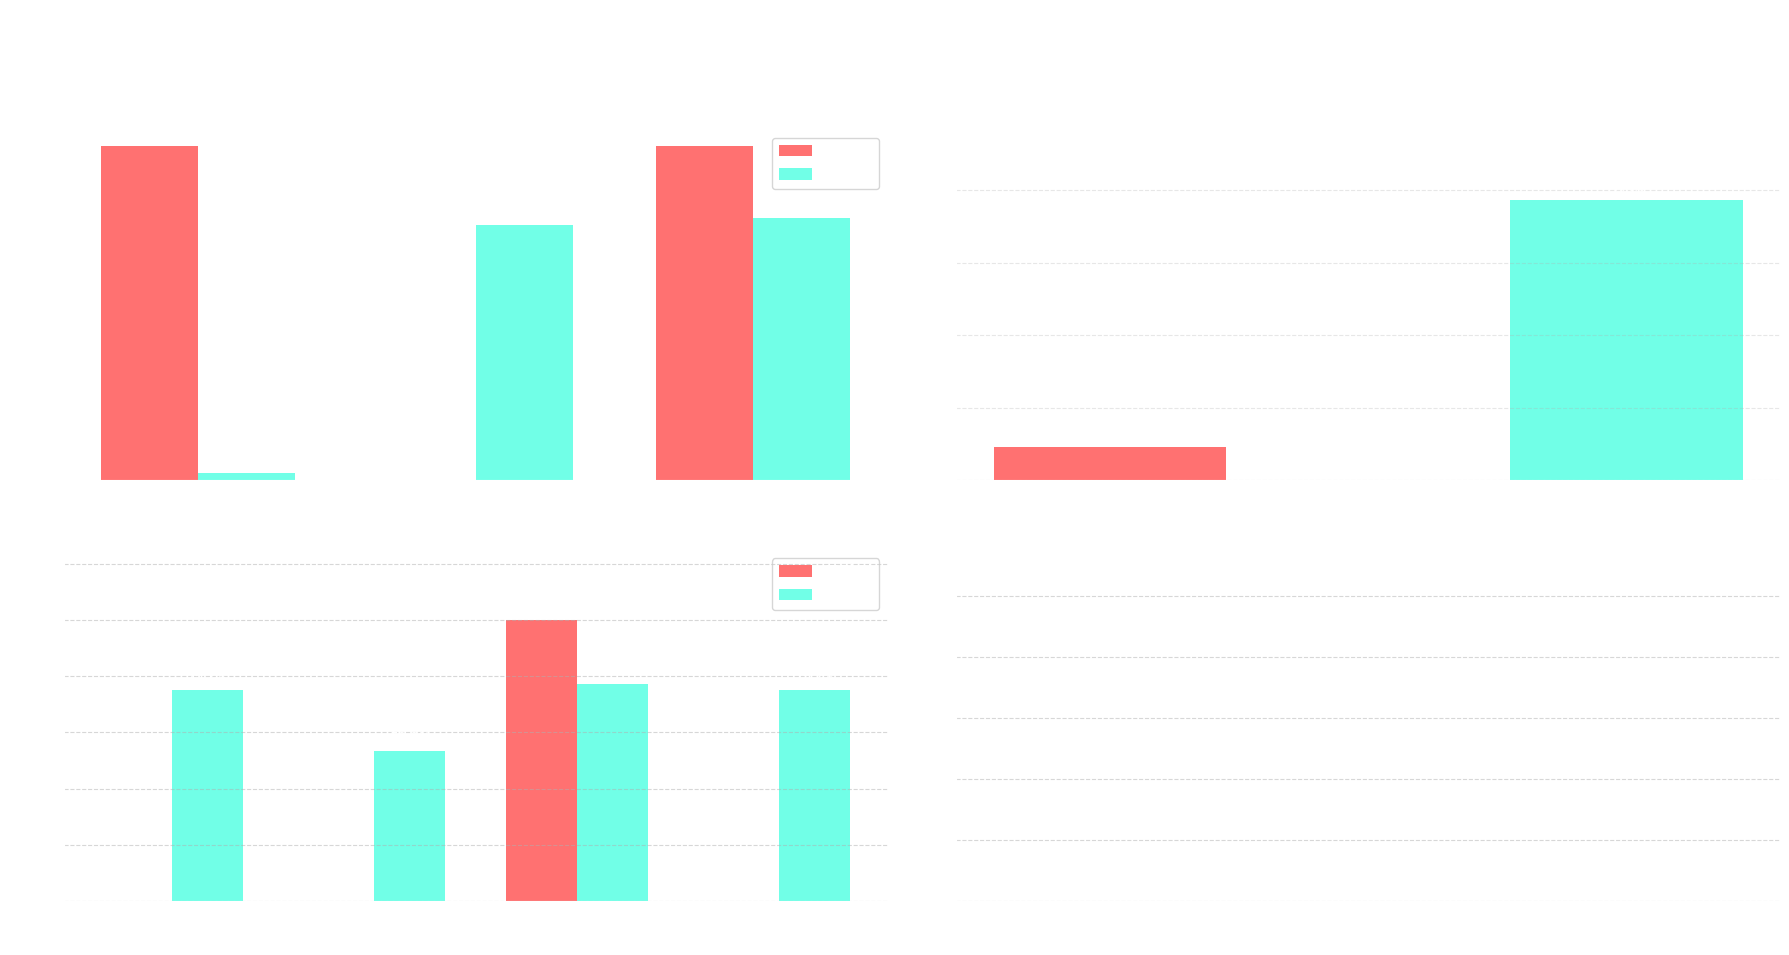

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Subplots 대시보드 생성 (2행 2열)
plt.close('all')
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
fig.suptitle('JSON-LD 규격 이행률 및 구조 종합', fontsize=20, fontweight='bold', y=0.98)


# 텍스트 출력 레이블 헬퍼 함수
def annotate_bars(ax, bars, is_percent=True, suffix=""):
    for bar in bars:
        height = bar.get_height()
        val_str = f'{height:.2f}%' if is_percent else f'{height:.2f}{suffix}'

        # 100% 수치에 대한 겹침 방지 안쪽 표시 처리
        if is_percent and f'{height:.2f}' == '100.00':
            y_pos = height - 8
            va = 'top'
        else:
            y_pos = height + 2
            va = 'bottom'

        ax.annotate(val_str,
                    xy=(bar.get_x() + bar.get_width() / 2, y_pos),
                    ha='center', va=va, fontsize=10, color='white')

def create_single_bar(ax, values, title, ylabel):
    bars = ax.bar(labels, values, color=colors)
    ax.set_title(title, fontsize=14, pad=12)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_ylim(0, 115)
    ax.grid(True, linestyle='--', alpha=0.5, axis='y')
    annotate_bars(ax, bars)

# [1,1] @type 필드 존재율
ax = axes[0, 0]
categories = ['루트 @type', '@graph 내 @type', '통합 @type']
x = np.arange(len(categories))
width = 0.35

rects1 = ax.bar(x - width/2, type_rate_orig, width, label='교정 전', color='#FF7171')
rects2 = ax.bar(x + width/2, type_rate_corr, width, label='교정 후', color='#71FFE7')
ax2.set_title('@type 포함 비', fontsize=15, pad=12, color='white', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend(title_fontsize=12, fontsize=12, loc='upper right')
ax.bar_label(rects1, fmt='%.1f%%', padding=3)
ax.bar_label(rects2, fmt='%.1f%%', padding=3)

# [1,2] Description 규격 이행률
ax2 = axes[0, 1]
bars2 = ax2.bar(['교정 전', '교정 후'], desc_rate_over50, color=['#FF7171', '#71FFE7'], width=0.45)
ax2.set_title('2. 50자 이상 작성된 Description 비율', fontsize=15, pad=12, color='white', fontweight='bold')
ax2.set_ylabel('비율 (%)', fontsize=12, color='white')
ax2.set_ylim(0, max(desc_rate_over50 + [10]) * 1.25)
ax2.grid(True, linestyle='--', alpha=0.3, axis='y')
ax2.bar_label(bars2, fmt='%.1f%%', padding=4, color='white', fontsize=10, fontweight='bold')

# [2,1] 의류 도메인 필수 속성 이행률
ax = axes[1, 0]
x_apparel = np.arange(len(apparel_attrs))
width = 0.35
rects_app1 = ax.bar(x_apparel - width/2, apparel_orig, width, label='교정 전', color='#71FFE7')
rects_app2 = ax.bar(x_apparel + width/2, apparel_corr, width, label='교정 후', color='#FF7171')
ax.set_title('3. 의류 도메인 필수 속성 이행률', fontsize=15, pad=12)
ax.set_ylabel('이행률 (%)', fontsize=12)
ax.set_xticks(x_apparel)
ax.set_xticklabels(apparel_attrs, fontsize=12)
ax.set_ylim(0, 115)
ax.grid(True, linestyle='--', alpha=0.5, axis='y')
ax.legend(title_fontsize=12, fontsize=12, loc='upper right')
annotate_bars(ax, rects_app1)
annotate_bars(ax, rects_app2)

# [2,2] 신뢰도(Confidence) 필드 존재율
ax = axes[1, 1]
bars4 = ax.bar(labels, conf_rate, color=colors)
ax.set_title('4. 신뢰도 요소 존재 비율', fontsize=15, pad=12)
ax.set_xlabel('교정 구분', fontsize=12) # Added x-axis label
ax.set_ylabel('존재율 (%)', fontsize=12)
ax.set_ylim(0, 115)
ax.grid(True, linestyle='--', alpha=0.5, axis='y')
annotate_bars(ax, bars4)


plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('JSON_LD_종합_이행률.png', dpi=300)
plt.show()